In [10]:
import pandas as pd

In [11]:
df=pd.read_csv('supervised_regression_20_features.csv')
df

,Temperature_C,Humidity_pct,Pressure_kPa,Wind_Speed_kmh,Rainfall_mm,Traffic_Level,Distance_km,Order_Weight_kg,Vehicle_Age_years,Driver_Experience_years,...,Delivery_Area_Density,Hour_Of_Day,Day_Of_Week,Is_Weekend,Restaurant_Preparation_Min,Courier_Stops_Before,Packaging_Delay_Min,Customer_Rating,Order_Priority,Delivery_Time_Minutes
0,33.636374,76.261913,102.407728,15.620646,0.266292,8,11.392714,8.737200,13,14,...,794.372243,0,6,0,6.238258,1,6.493570,2.031360,3,65.42
1,21.238502,75.455210,104.958065,18.945737,0.397658,3,16.804434,16.008007,12,11,...,292.776284,7,1,0,6.349932,7,9.481093,4.380234,2,69.04
2,36.768123,32.229078,95.409773,44.311472,0.375084,10,25.029160,14.365631,10,13,...,510.889099,12,6,0,18.404071,5,9.257543,3.165612,1,119.38
3,30.802617,18.115709,97.449194,3.788734,0.129707,9,27.483481,13.487088,2,18,...,529.109876,18,3,1,39.374743,7,8.360639,4.208426,3,108.03
4,8.484562,40.822959,100.977407,5.024301,8.349768,8,31.025250,0.839202,3,5,...,259.038107,8,2,0,6.749474,2,2.037147,2.445275,2,78.27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,21.529640,84.049220,102.361755,39.579968,0.316045,8,1.743799,19.458780,7,14,...,353.830299,7,0,1,8.064556,1,8.022377,4.655010,2,65.59
9996,16.445852,59.876147,100.478443,43.167834,0.584213,1,18.385567,11.455884,11,14,...,591.035307,0,4,0,18.954192,5,6.126626,3.229551,2,74.92
9997,11.117838,87.006141,101.006966,35.977718,2.472404,1,9.692991,0.925391,15,12,...,788.080925,18,4,0,29.992649,0,7.788915,2.459082,1,60.49
9998,18.816185,72.018276,104.728105,15.138264,0.938458,9,26.041450,15.917788,12,5,...,546.657341,2,1,1,9.729518,4,8.019552,4.741830,2,90.34


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Temperature_C               10000 non-null  float64
 1   Humidity_pct                10000 non-null  float64
 2   Pressure_kPa                10000 non-null  float64
 3   Wind_Speed_kmh              10000 non-null  float64
 4   Rainfall_mm                 10000 non-null  float64
 5   Traffic_Level               10000 non-null  int64  
 6   Distance_km                 10000 non-null  float64
 7   Order_Weight_kg             10000 non-null  float64
 8   Vehicle_Age_years           10000 non-null  int64  
 9   Driver_Experience_years     10000 non-null  int64  
 10  Road_Quality_Score          10000 non-null  float64
 11  Delivery_Area_Density       10000 non-null  float64
 12  Hour_Of_Day                 10000 non-null  int64  
 13  Day_Of_Week                 10000 non-null 

In [13]:
df.isnull().sum()

Temperature_C                 0
Humidity_pct                  0
Pressure_kPa                  0
Wind_Speed_kmh                0
Rainfall_mm                   0
Traffic_Level                 0
Distance_km                   0
Order_Weight_kg               0
Vehicle_Age_years             0
Driver_Experience_years       0
Road_Quality_Score            0
Delivery_Area_Density         0
Hour_Of_Day                   0
Day_Of_Week                   0
Is_Weekend                    0
Restaurant_Preparation_Min    0
Courier_Stops_Before          0
Packaging_Delay_Min           0
Customer_Rating               0
Order_Priority                0
Delivery_Time_Minutes         0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt


In [16]:
df.describe()

,Temperature_C,Humidity_pct,Pressure_kPa,Wind_Speed_kmh,Rainfall_mm,Traffic_Level,Distance_km,Order_Weight_kg,Vehicle_Age_years,Driver_Experience_years,...,Delivery_Area_Density,Hour_Of_Day,Day_Of_Week,Is_Weekend,Restaurant_Preparation_Min,Courier_Stops_Before,Packaging_Delay_Min,Customer_Rating,Order_Priority,Delivery_Time_Minutes
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000
mean,23.393499,57.749533,100.024817,22.575126,1.998947,5.504900,17.907955,10.094425,7.517300,12.455600,...,510.256314,11.491500,2.987700,0.497300,24.929287,3.487100,5.979939,3.007345,2.01160,81.175837
std,10.664174,24.560142,2.884902,13.030219,1.975442,2.873918,9.953089,5.687092,4.582227,7.453213,...,286.663566,6.929916,2.004333,0.500018,11.518363,2.271288,3.479340,1.155831,0.82069,20.867888
min,5.011634,15.001119,95.000472,0.001236,0.000529,1.000000,0.500458,0.203106,0.000000,0.000000,...,10.037855,0.000000,0.000000,0.000000,5.015489,0.000000,0.000310,1.000194,1.00000,18.150000
25%,14.103406,36.247999,97.531413,11.131462,0.578735,3.000000,9.446010,5.127218,4.000000,6.000000,...,261.240475,6.000000,1.000000,0.000000,14.848962,2.000000,2.908059,2.014502,1.00000,65.980000
50%,23.437155,58.150553,100.021138,22.754114,1.382969,6.000000,17.945711,10.122903,8.000000,12.000000,...,512.746722,11.000000,3.000000,0.000000,24.890526,3.000000,5.968439,2.985957,2.00000,80.725000
75%,32.590075,78.914972,102.572616,33.818068,2.793556,8.000000,26.637298,14.909917,11.000000,19.000000,...,761.907504,18.000000,5.000000,1.000000,34.800047,5.000000,9.020176,4.016871,3.00000,95.420000
max,41.999150,99.995517,104.999825,44.995912,22.311564,10.000000,34.988262,19.999050,15.000000,25.000000,...,999.935354,23.000000,6.000000,1.000000,44.994978,7.000000,11.997904,4.999279,3.00000,158.690000


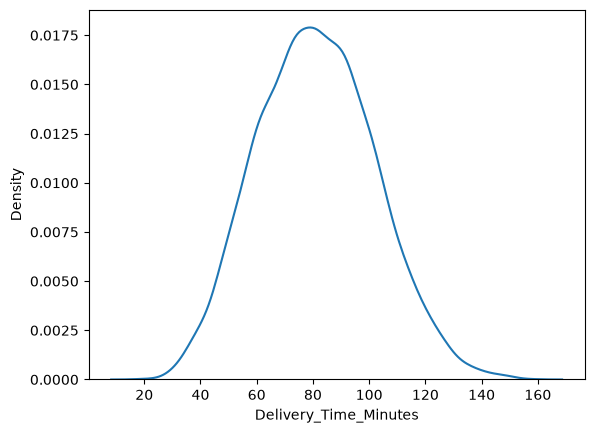

In [17]:
sns.kdeplot(df['Delivery_Time_Minutes'])
plt.show()

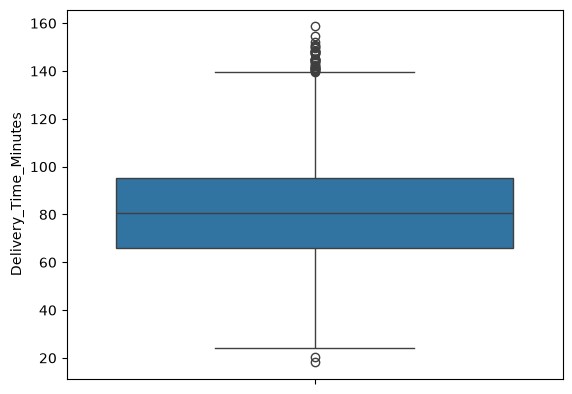

In [18]:
sns.boxplot(df['Delivery_Time_Minutes'])
plt.show()

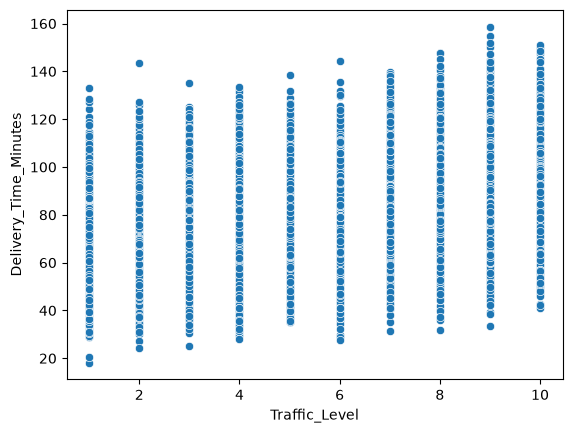

In [19]:
sns.scatterplot(x='Traffic_Level',y='Delivery_Time_Minutes',data=df)
plt.show()

In [20]:
df.columns

Index(['Temperature_C', 'Humidity_pct', 'Pressure_kPa', 'Wind_Speed_kmh',
       'Rainfall_mm', 'Traffic_Level', 'Distance_km', 'Order_Weight_kg',
       'Vehicle_Age_years', 'Driver_Experience_years', 'Road_Quality_Score',
       'Delivery_Area_Density', 'Hour_Of_Day', 'Day_Of_Week', 'Is_Weekend',
       'Restaurant_Preparation_Min', 'Courier_Stops_Before',
       'Packaging_Delay_Min', 'Customer_Rating', 'Order_Priority',
       'Delivery_Time_Minutes'],
      dtype='str')

In [21]:
df[['Temperature_C', 'Humidity_pct', 'Pressure_kPa', 'Wind_Speed_kmh',
       'Rainfall_mm', 'Traffic_Level', 'Distance_km', 'Order_Weight_kg',
       'Vehicle_Age_years', 'Driver_Experience_years',
       'Delivery_Area_Density', 'Hour_Of_Day', 'Day_Of_Week', 'Is_Weekend',
       'Restaurant_Preparation_Min', 'Courier_Stops_Before',
       'Packaging_Delay_Min', 'Customer_Rating', 'Order_Priority',
       'Delivery_Time_Minutes']].corr()

,Temperature_C,Humidity_pct,Pressure_kPa,Wind_Speed_kmh,Rainfall_mm,Traffic_Level,Distance_km,Order_Weight_kg,Vehicle_Age_years,Driver_Experience_years,Delivery_Area_Density,Hour_Of_Day,Day_Of_Week,Is_Weekend,Restaurant_Preparation_Min,Courier_Stops_Before,Packaging_Delay_Min,Customer_Rating,Order_Priority,Delivery_Time_Minutes
Temperature_C,1.000000,-0.003246,-0.005441,0.034638,-0.016495,0.001098,0.010445,-0.002630,-0.004272,-0.009055,-0.002045,0.003335,-0.005594,0.001906,-0.013544,0.017885,0.004079,-0.001224,0.033444,0.270944
Humidity_pct,-0.003246,1.000000,-0.005421,-0.001059,0.005323,0.027701,-0.004069,-0.000465,-0.011930,0.007519,0.012926,0.002740,0.002997,-0.007520,-0.003454,0.007282,0.007099,-0.001692,-0.000692,0.097694
Pressure_kPa,-0.005441,-0.005421,1.000000,0.006792,-0.020232,0.003995,-0.011661,-0.014269,0.007486,-0.001039,0.008956,0.000560,0.008590,0.000577,-0.007873,-0.008590,-0.015976,-0.010180,-0.004572,-0.016528
Wind_Speed_kmh,0.034638,-0.001059,0.006792,1.000000,-0.012659,-0.012777,0.007286,0.012501,0.013788,-0.002956,0.000841,-0.000514,0.000141,0.013731,-0.001777,0.008972,-0.000762,0.012757,0.000266,0.249352
Rainfall_mm,-0.016495,0.005323,-0.020232,-0.012659,1.000000,0.008991,-0.012251,-0.003631,0.003070,-0.004054,-0.007974,-0.001295,0.002368,-0.003713,0.021211,-0.009389,0.010885,-0.010161,-0.001619,0.120135
Traffic_Level,0.001098,0.027701,0.003995,-0.012777,0.008991,1.000000,-0.004079,0.011437,0.011370,0.004168,0.014729,0.006405,0.019100,-0.005767,-0.012017,0.010750,0.000844,-0.004360,-0.003289,0.361896
Distance_km,0.010445,-0.004069,-0.011661,0.007286,-0.012251,-0.004079,1.000000,0.001343,-0.007413,-0.003055,0.005764,-0.009260,-0.023767,-0.010336,-0.010835,0.003132,-0.001284,0.007938,-0.009319,0.669611
Order_Weight_kg,-0.002630,-0.000465,-0.014269,0.012501,-0.003631,0.011437,0.001343,1.000000,0.002966,-0.006592,0.004679,0.009228,0.008829,0.018915,0.002092,0.001350,-0.003564,-0.019816,-0.017111,0.238224
Vehicle_Age_years,-0.004272,-0.011930,0.007486,0.013788,0.003070,0.011370,-0.007413,0.002966,1.000000,-0.010316,-0.012387,-0.011223,-0.010893,-0.009539,0.008678,-0.002592,0.020464,-0.011827,-0.018882,0.002538
Driver_Experience_years,-0.009055,0.007519,-0.001039,-0.002956,-0.004054,0.004168,-0.003055,-0.006592,-0.010316,1.000000,-0.003410,0.012134,0.020807,0.006234,0.019229,0.000560,0.002767,0.001929,0.001278,-0.037457


In [22]:
corr=df[['Temperature_C', 'Humidity_pct', 'Pressure_kPa', 'Wind_Speed_kmh',
       'Rainfall_mm', 'Traffic_Level', 'Distance_km', 'Order_Weight_kg',
       'Vehicle_Age_years', 'Driver_Experience_years',
       'Delivery_Area_Density', 'Hour_Of_Day', 'Day_Of_Week', 'Is_Weekend',
       'Restaurant_Preparation_Min', 'Courier_Stops_Before',
       'Packaging_Delay_Min', 'Customer_Rating', 'Order_Priority',
       'Delivery_Time_Minutes']].corr()

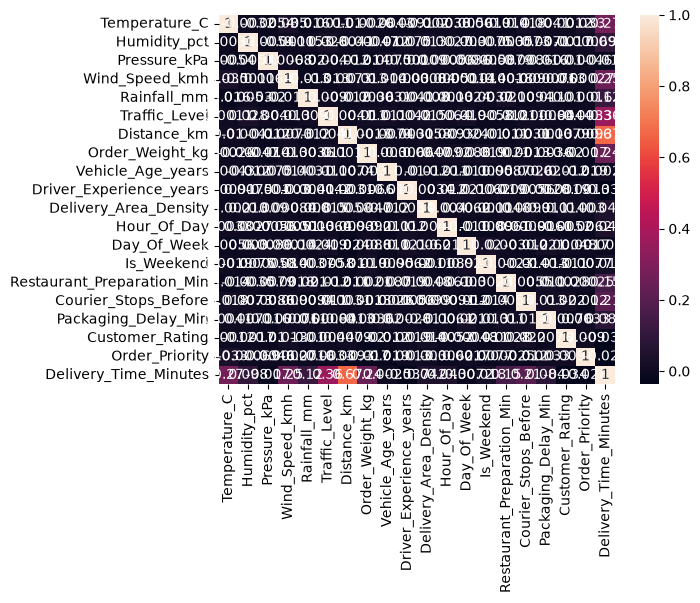

In [23]:
sns.heatmap(corr,annot=True)
plt.show()

clear the out liers IQR and Z-score

In [24]:
df['Delivery_Time_Minutes'].describe()

count    10000.000000
mean        81.175837
std         20.867888
min         18.150000
25%         65.980000
50%         80.725000
75%         95.420000
max        158.690000
Name: Delivery_Time_Minutes, dtype: float64

In [25]:
from scipy import stats
import numpy as np

In [26]:
Q1 = df['Delivery_Time_Minutes'].quantile(0.25)
Q3 = df['Delivery_Time_Minutes'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['Delivery_Time_Minutes'] = df['Delivery_Time_Minutes'].clip(lower, upper)

In [27]:
from scipy import stats
import numpy as np

z = np.abs(stats.zscore(df['Delivery_Time_Minutes']))

df = df[z < 3]

In [28]:
df['Delivery_Time_Minutes'].describe()

count    10000.000000
mean        81.154378
std         20.800050
min         21.820000
25%         65.980000
50%         80.725000
75%         95.420000
max        139.580000
Name: Delivery_Time_Minutes, dtype: float64

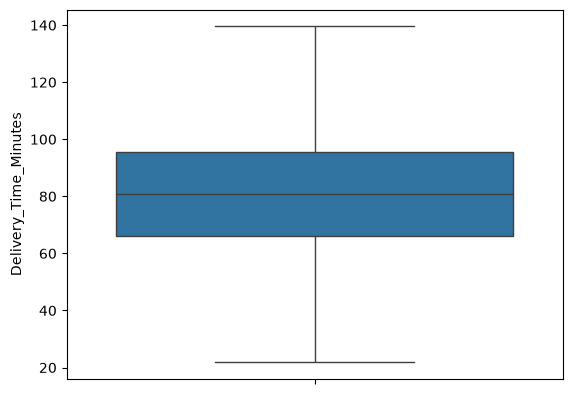

In [29]:
sns.boxplot(df['Delivery_Time_Minutes'])
plt.show()

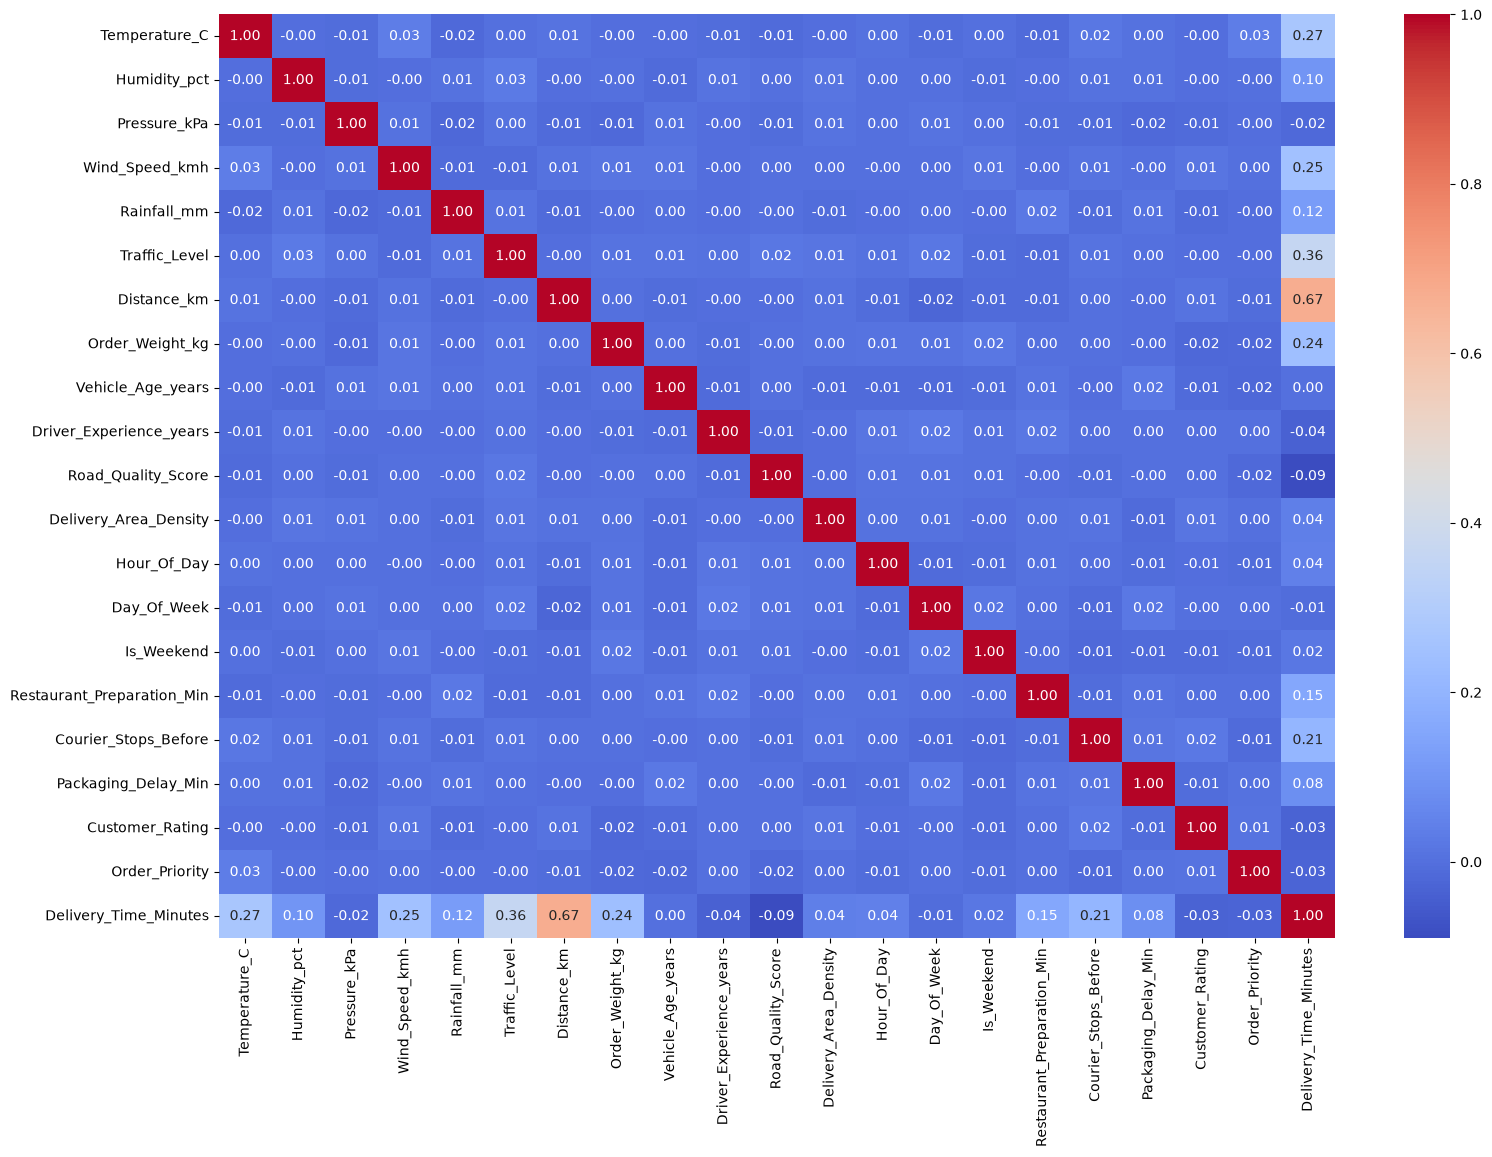

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr(numeric_only=True)

plt.figure(figsize=(18,12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [31]:
df.columns

Index(['Temperature_C', 'Humidity_pct', 'Pressure_kPa', 'Wind_Speed_kmh',
       'Rainfall_mm', 'Traffic_Level', 'Distance_km', 'Order_Weight_kg',
       'Vehicle_Age_years', 'Driver_Experience_years', 'Road_Quality_Score',
       'Delivery_Area_Density', 'Hour_Of_Day', 'Day_Of_Week', 'Is_Weekend',
       'Restaurant_Preparation_Min', 'Courier_Stops_Before',
       'Packaging_Delay_Min', 'Customer_Rating', 'Order_Priority',
       'Delivery_Time_Minutes'],
      dtype='str')

In [32]:
df.drop(columns=['Pressure_kPa', 'Vehicle_Age_years','Driver_Experience_years','Road_Quality_Score','Delivery_Area_Density', 'Hour_Of_Day', 'Day_Of_Week', 'Is_Weekend','Packaging_Delay_Min', 'Customer_Rating', 'Order_Priority'], inplace=True)

In [33]:
df.columns

Index(['Temperature_C', 'Humidity_pct', 'Wind_Speed_kmh', 'Rainfall_mm',
       'Traffic_Level', 'Distance_km', 'Order_Weight_kg',
       'Restaurant_Preparation_Min', 'Courier_Stops_Before',
       'Delivery_Time_Minutes'],
      dtype='str')

In [34]:
from sklearn.model_selection import train_test_split

In [35]:
x=df.drop('Delivery_Time_Minutes',axis=1 )
y=df['Delivery_Time_Minutes']

In [36]:
x_train , x_test, y_train , y_test = train_test_split(x,y,test_size=0.20, random_state=100)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(8000, 9)
(2000, 9)
(8000,)
(2000,)


In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [38]:
from sklearn.linear_model import LinearRegression

li=LinearRegression()
li.fit(x_train, y_train)
y_pred=li.predict(x_train)
print(y_pred)

from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_train,y_pred))
print(mean_absolute_error(y_train,y_pred))

[87.4730268  50.9565893  54.39088329 ... 99.55231922 95.09137478
 60.19131255]
0.8544014433371606
6.354120390198998


In [39]:
li=LinearRegression()
li.fit(x_train, y_train)
y_pred=li.predict(x_test)
print(y_pred)


from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))

[ 45.70188748  90.32111874  84.74197736 ...  95.95029234  75.69792009
 100.89027135]
0.8489011601539367
6.417516769341041


In [40]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor()
dt.fit(x_train, y_train)

y_pred = dt.predict(x_train)

from sklearn.metrics import r2_score, mean_absolute_error

print(r2_score(y_train, y_pred))
print(mean_absolute_error(y_train, y_pred))

1.0
0.0


In [41]:
y_pred = dt.predict(x_test)

print(r2_score(y_test, y_pred))
print(mean_absolute_error(y_test, y_pred))

0.6614624574049082
9.41243


In [42]:
from sklearn.ensemble import RandomForestRegressor

rf=RandomForestRegressor()
rf.fit(x_train, y_train)
y_pred=rf.predict(x_train)
print(y_pred)

from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_train,y_pred))
print(mean_absolute_error(y_train,y_pred))

[ 93.6144  46.6583  52.2493 ...  93.6937 103.8785  55.608 ]
0.9799452126092036
2.3222362000000003


In [43]:
rf=RandomForestRegressor()
rf.fit(x_train, y_train)
y_pred=rf.predict(x_test)
print(y_pred)


from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))

[38.5316 81.6974 79.3614 ... 96.3751 79.3604 92.0189]
0.8622713884276427
6.0989096


In [44]:
from sklearn.neighbors import KNeighborsRegressor

knr=KNeighborsRegressor()
knr.fit(x_train, y_train)
y_pred=knr.predict(x_train)
print(y_pred)

from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_train,y_pred))
print(mean_absolute_error(y_train,y_pred))


[78.422 48.166 59.538 ... 93.754 88.834 56.958]
0.8266829598054234
6.885314749999999


In [45]:
knr=KNeighborsRegressor()
knr.fit(x_train, y_train)
y_pred=knr.predict(x_test)
print(y_pred)


from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))

[51.24  85.414 87.14  ... 89.576 70.752 89.03 ]
0.7248375022924902
8.608996


In [46]:
from sklearn.svm import SVR

sv=SVR()
sv.fit(x_train,y_train)
y_pred=sv.predict(x_train)
y_pred

from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_train,y_pred))
print(mean_absolute_error(y_train,y_pred))

0.8521819376847082
6.361591324072647


In [47]:
sv=SVR()
sv.fit(x_train,y_train)
y_pred=sv.predict(x_test)
y_pred


from sklearn.metrics import r2_score,mean_absolute_error
print(r2_score(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))

0.8453044526716263
6.457479515744366


In [48]:
# train - hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_param = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 1.0],
    "bootstrap": [True, False]
}

rf_model = RandomForestRegressor()

rf_cv = RandomizedSearchCV(rf_model, rf_param, cv=5, n_iter=10, random_state=42)

rf_cv.fit(x_train, y_train)

print(rf_cv.best_params_)

{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'bootstrap': False}


In [49]:
# test - hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_param = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 10, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 1.0],
    "bootstrap": [True, False]
}

rf_model = RandomForestRegressor()

rf_cv = RandomizedSearchCV(rf_model, rf_param, cv=5, n_iter=10, random_state=42)

rf_cv.fit(x_test, y_test)

print(rf_cv.best_params_)

{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': None, 'bootstrap': False}


In [50]:
# {'n_estimators': 300, 'min_samples_split': 20, 'min_samples_leaf': 2, 'max_depth': 10}

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="log2",
    bootstrap=False
)

rf.fit(x_train, y_train)

y_train_predict = rf.predict(x_train)

# Evaluation - train
print("Random Forest R2 Score:", r2_score(y_train, y_train_predict))
print("Random Forest MAE:", mean_absolute_error(y_train, y_train_predict))

Random Forest R2 Score: 0.9934256956303699
Random Forest MAE: 1.2342038458333338


In [51]:
# {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_depth': None}

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="log2",
    bootstrap=False
)

rf.fit(x_train, y_train)

y_test_predict = rf.predict(x_test)

# Evaluation - test
print("Random Forest R2 Score:", r2_score(y_test, y_test_predict))
print("Random Forest MAE:", mean_absolute_error(y_test, y_test_predict))

Random Forest R2 Score: 0.8646638110421423
Random Forest MAE: 6.020641937499999


In [52]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor()

gb.fit(x_train, y_train)

y_train_predict = gb.predict(x_train)

from sklearn.metrics import r2_score, mean_absolute_error

print("Gradient Boosting R2 Score:", r2_score(y_train, y_train_predict))
print("Gradient Boosting MAE:", mean_absolute_error(y_train, y_train_predict))

Gradient Boosting R2 Score: 0.9093940071441329
Gradient Boosting MAE: 5.015111015167329


In [53]:
y_test_predict = gb.predict(x_test)

print("Gradient Boosting R2 Score:", r2_score(y_test, y_test_predict))
print("Gradient Boosting MAE:", mean_absolute_error(y_test, y_test_predict))

Gradient Boosting R2 Score: 0.8894783823764216
Gradient Boosting MAE: 5.439760061127426


In [54]:
from xgboost import XGBRegressor

xgb = XGBRegressor()

xgb.fit(x_train, y_train)

y_train_predict = xgb.predict(x_train)

from sklearn.metrics import r2_score, mean_absolute_error

print("XGBoost R2 Score:", r2_score(y_train, y_train_predict))
print("XGBoost MAE:", mean_absolute_error(y_train, y_train_predict))

XGBoost R2 Score: 0.9722263807521225
XGBoost MAE: 2.6425279138565063


In [55]:
y_test_predict = xgb.predict(x_test)

print("XGBoost R2 Score:", r2_score(y_test, y_test_predict))
print("XGBoost MAE:", mean_absolute_error(y_test, y_test_predict))

XGBoost R2 Score: 0.8726491749916206
XGBoost MAE: 5.874323979492187


In [56]:
from lightgbm import LGBMRegressor

lgb = LGBMRegressor()

lgb.fit(x_train, y_train)

y_train_predict = lgb.predict(x_train)

from sklearn.metrics import r2_score, mean_absolute_error

print("LightGBM R2 Score:", r2_score(y_train, y_train_predict))
print("LightGBM MAE:", mean_absolute_error(y_train, y_train_predict))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001087 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1804
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 9
[LightGBM] [Info] Start training from score 81.234151
LightGBM R2 Score: 0.9379162760157909
LightGBM MAE: 4.134099823045159


In [57]:
y_test_predict = lgb.predict(x_test)

print("LightGBM R2 Score:", r2_score(y_test, y_test_predict))
print("LightGBM MAE:", mean_absolute_error(y_test, y_test_predict))

LightGBM R2 Score: 0.8912908093310955
LightGBM MAE: 5.38572154231368


In [58]:
# train - hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMRegressor

lgb_param = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [-1, 5, 10, 20, 30],
    "learning_rate": [0.01, 0.05, 0.1],
    "num_leaves": [15, 20, 31, 50],
    "min_child_samples": [1, 2, 4, 8],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "subsample": [0.7, 0.8, 1.0]
}

lgb_model = LGBMRegressor()

lgb_cv = RandomizedSearchCV(
    lgb_model, lgb_param, cv=5, n_iter=10, random_state=42
)

lgb_cv.fit(x_train, y_train)

print(lgb_cv.best_params_)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000375 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1804
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 9
[LightGBM] [Info] Start training from score 81.279381
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000370 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1804
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 9
[LightGBM] [Info] Start training from score 81.309194
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.00035

In [59]:
# test - hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMRegressor

lgb_param = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [-1, 5, 10, 20, 30],
    "learning_rate": [0.01, 0.05, 0.1],
    "num_leaves": [15, 20, 31, 50],
    "min_child_samples": [1, 2, 4, 8],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "subsample": [0.7, 0.8, 1.0]
}

lgb_model = LGBMRegressor()

lgb_cv = RandomizedSearchCV(
    lgb_model, lgb_param, cv=5, n_iter=10, random_state=42
)

lgb_cv.fit(x_test, y_test)

print(lgb_cv.best_params_)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000183 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1804
[LightGBM] [Info] Number of data points in the train set: 1600, number of used features: 9
[LightGBM] [Info] Start training from score 80.977906
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, 

In [60]:
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error

rf = LGBMRegressor(
    n_estimators=350,
    max_depth=20,
    learning_rate=0.1,
    num_leaves=15,
    min_child_samples=1,
    colsample_bytree=0.8,
    subsample=1.0
)

rf.fit(x_train, y_train)

y_train_predict = rf.predict(x_train)

# Evaluation - train
print("LightGBM R2 Score:", r2_score(y_train, y_train_predict))
print("LightGBM MAE:", mean_absolute_error(y_train, y_train_predict))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000492 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1804
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 9
[LightGBM] [Info] Start training from score 81.234151
LightGBM R2 Score: 0.9457445070056145
LightGBM MAE: 3.861334139014814


In [61]:
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error

rf = LGBMRegressor(
    n_estimators=350,
    max_depth=20,
    learning_rate=0.1,
    num_leaves=15,
    min_child_samples=1,
    colsample_bytree=0.8,
    subsample=1.0
)

rf.fit(x_train, y_train)

y_test_predict = rf.predict(x_test)

# Evaluation - test
print("LightGBM R2 Score:", r2_score(y_test, y_test_predict))
print("LightGBM MAE:", mean_absolute_error(y_test, y_test_predict))

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000400 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1804
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 9
[LightGBM] [Info] Start training from score 81.234151
LightGBM R2 Score: 0.8931604606508841
LightGBM MAE: 5.377359208962268


In [62]:
# train - hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor

gb_param = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", None],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}

gb_model = GradientBoostingRegressor()

gb_cv = RandomizedSearchCV(
    gb_model, gb_param, cv=5, n_iter=20, random_state=42
)

gb_cv.fit(x_train, y_train)

print(gb_cv.best_params_)

{'subsample': 0.9, 'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'max_depth': 5, 'learning_rate': 0.05}


In [63]:
# test - hyperparameter tuning

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor

gb_param = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", None],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}

gb_model = GradientBoostingRegressor()

gb_cv = RandomizedSearchCV(
    gb_model, gb_param, cv=5, n_iter=20, random_state=42
)

gb_cv.fit(x_train, y_train)

print(gb_cv.best_params_)

{'subsample': 0.9, 'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'max_depth': 5, 'learning_rate': 0.05}


In [64]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

rf = GradientBoostingRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    subsample=0.8
)

rf.fit(x_train, y_train)

y_train_predict = rf.predict(x_train)

# Evaluation - train
print("Gradient Boosting R2 Score:", r2_score(y_train, y_train_predict))
print("Gradient Boosting MAE:", mean_absolute_error(y_train, y_train_predict))

Gradient Boosting R2 Score: 0.9515675393095991
Gradient Boosting MAE: 3.6331640909482266


In [65]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error

rf = GradientBoostingRegressor(
    n_estimators=600,
    max_depth=3,
    learning_rate=0.1,
    min_samples_split=39,
    min_samples_leaf=5,
    max_features="log2",
    subsample=0.9
)

rf.fit(x_train, y_train)

y_test_predict = rf.predict(x_test)

# Evaluation - test
print("Gradient Boosting R2 Score:", r2_score(y_test, y_test_predict))
print("Gradient Boosting MAE:", mean_absolute_error(y_test, y_test_predict))

Gradient Boosting R2 Score: 0.8985378893585183
Gradient Boosting MAE: 5.229092323494596
